# V14: fixed route expansion stops before GPU

**Uniform incremental loss reduction0.0002801fails the frozen>0.0005gate.**
No GPU or official submission. Retain the actual best0.82987/rank23; rank<=19
remains the objective. The candidate changes only10%to15%work, keeping20%rows,
JS/work ranking, expert mixture/T1/8192packing/context4096/source fixed.

Both route arms use the same full reverse-Gemma cache. Comparisons to deployed
H60are separate unmatched-cohort diagnostics. Original votes overlap checkpoint
training; intervals and gains are descriptive, not independent CV or score forecasts.
The prospective rule and gate were committed before this replay.

,cohort,rows,parent_selected_rows,candidate_selected_rows,parent_common_cache_log_loss,candidate_log_loss,incremental_loss_reduction,descriptive_paired_group95
0,control,256,42,51,0.598234,0.598407,-0.000173,"[-0.000772, 0.00025]"
1,uniform,512,83,102,0.652988,0.652708,0.000280,"[-0.000011, 0.00063]"
2,long,64,6,9,0.896484,0.896140,0.000344,"[-0.001546, 0.002885]"


,control,uniform,long
winner_model_a,0.000291,0.000129,0.002126
winner_model_b,-0.000802,0.000564,-0.000990
winner_tie,0.000000,0.000182,0.000000


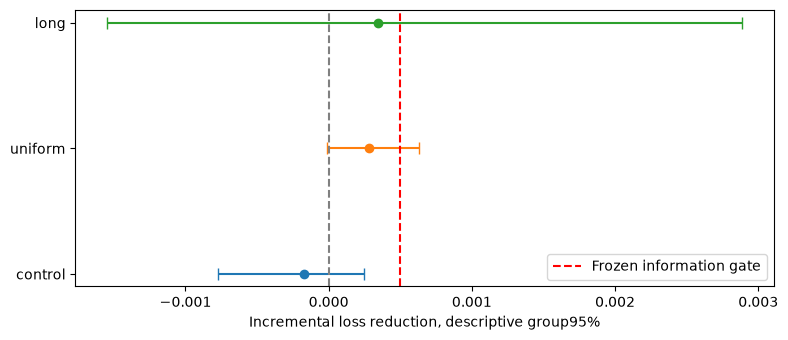

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_014'
def read(name):return json.loads((PUB/name).read_text())
q=read('H61_cached_replay.json');phase=read('span_plan.json')
rows=[{'cohort':name,**r} for name,r in q['coverage'].items() if name!='test']
display(pd.DataFrame(rows)[['cohort','rows','parent_selected_rows','candidate_selected_rows',
 'parent_common_cache_log_loss','candidate_log_loss','incremental_loss_reduction','descriptive_paired_group95']])
display(pd.DataFrame({r['cohort']:r['class_incremental_loss_reduction'] for r in rows}))
fig,ax=plt.subplots(figsize=(8,3.5))
for i,r in enumerate(rows):
 lo,hi=r['descriptive_paired_group95'];gain=r['incremental_loss_reduction']
 ax.errorbar(gain,i,xerr=[[max(0,gain-lo)],[max(0,hi-gain)]],fmt='o',capsize=4)
ax.axvline(0,color='gray',linestyle='--');ax.axvline(.0005,color='red',linestyle='--',label='Frozen information gate')
ax.set_yticks(range(len(rows)),[r['cohort'] for r in rows]);ax.set_xlabel('Incremental loss reduction, descriptive group95%')
ax.legend();fig.tight_layout();plt.show()

,parent_selected_rows,candidate_selected_rows,common_selected_rows,added_rows,dropped_rows,parent_work_fraction,candidate_work_fraction,parent_common_cache_max_abs_vs_actual_deployed
cohort,,,,,,,,
control,42,51,42,9,0,0.099494,0.121643,0.00000
uniform,83,102,83,19,0,0.099805,0.127138,0.00005
long,6,9,6,3,0,0.089096,0.136209,0.00000
test,0,0,0,0,0,0.000000,0.000000,0.00000


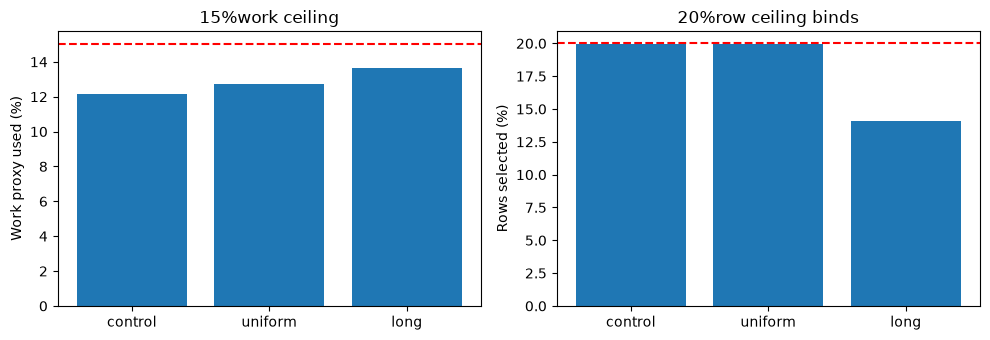

Full versus routed cohort differences are not canonical raw-identity checks.


In [2]:
coverage=pd.DataFrame([{'cohort':name,**r} for name,r in q['coverage'].items()]).set_index('cohort')
display(coverage[['parent_selected_rows','candidate_selected_rows','common_selected_rows','added_rows','dropped_rows',
 'parent_work_fraction','candidate_work_fraction','parent_common_cache_max_abs_vs_actual_deployed']])
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
names=['control','uniform','long'];x=np.arange(len(names));values=coverage.loc[names]
axes[0].bar(x,100*values['candidate_work_fraction']);axes[0].axhline(15,color='red',linestyle='--')
axes[0].set_xticks(x,names);axes[0].set_ylabel('Work proxy used (%)');axes[0].set_title('15%work ceiling')
axes[1].bar(x,100*values['candidate_selected_rows']/values['rows']);axes[1].axhline(20,color='red',linestyle='--')
axes[1].set_xticks(x,names);axes[1].set_ylabel('Rows selected (%)');axes[1].set_title('20%row ceiling binds')
fig.tight_layout();plt.show()
print('Full versus routed cohort differences are not canonical raw-identity checks.')

In [3]:
print('Decision:',q['decision'])
print('Information gate passed:',q['information_gate_passed'])
print('New GPU executions:',q['new_gpu_executions'],'; CPU elapsed seconds:',q['elapsed_cpu_seconds'])
print('Quality variants tested:',q['quality_variants_tested'],'; independent local quality:',q['independent_local_quality'])
print('Original deadline:',phase['deadline'],'; unused public cap seconds:',phase['gpu_session_seconds_cap'])
leader=read('final_leaderboard.json') if (PUB/'final_leaderboard.json').exists() else json.loads((REPO/'results/span_013/final_leaderboard.json').read_text())
display(pd.DataFrame([leader]))
print('Retained official0.82987/rank23is separate from this CPU-only test; the rank<=19goal is not achieved.')

Decision: Stop H61 without GPU; retain official0.82987
Information gate passed: False
New GPU executions: 0 ; CPU elapsed seconds: 0.9095300550106913
Quality variants tested: 1 ; independent local quality: False
Original deadline: 2026-11-10T02:23:36.027583+00:00 ; unused public cap seconds: 6000


,observed_at,complete,team_id,rank,teams,score,rank19_score,rank20_score,leader_score,target_achieved,latest_team_submission_date
0,2026-11-08T02:33:29.906340+00:00,True,17244411,23,312,0.82987,0.82915,0.82915,0.82702,False,2026-11-07T20:07:11.890Z


Retained official0.82987/rank23is separate from this CPU-only test; the rank<=19goal is not achieved.
